# Position held: individuals with a dated position, per century

In [1]:
import json
import re
import sys

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only: birth years
POSITIONS_PATH = '../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/position_held_P39_statements.json'  # raw P39 statements
TARGETS_PATH = '../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/targets.json'  # raw labels of the positions
FIRST_CENTURY, LAST_CENTURY = -500, 1900
CENTURY = 100  # years
EXAMPLE_BIRTH_YEARS = (700, 799)  # century of birth of the example individuals of Figure 3
OCCUPATION_BIRTH_YEARS = (1600, 1699)  # century of birth of the scientists and artists of Figures 4 and 5
OCCUPATIONS = {'Discovery/Science': 'scientists', 'Culture': 'artists'}  # main meta occupation shown in Figures 4 and 5
EXAMPLES = 10  # most-linked individuals shown in each example figure
SPAN_COLORS = {'Before the first position': ORANGE, 'Positions held (first start → last end)': PURPLE, 'After the last position': GREEN}

pl.Config.set_tbl_rows(40)
apply_style()

## Data
Raw Wikidata position held (P39) statements, deprecated ones dropped. A position counts only with both a start time (P580) and an end time (P582); a position without them, or with a point in time (P585) only, does not count. Individuals are placed in their century of birth (`individual_enriched`, Wikidata or estimated).

In [2]:
def year(value):
    sign, digits = re.match(r'([+-]?)(\d+)-', value['time']).groups()
    return -int(digits) if sign == '-' else int(digits)


raw = json.load(open(POSITIONS_PATH))
positions = pl.DataFrame(
    [
        {'qid': qid, 'position_qid': statement['target'],
         'start_year': year(statement['start']) if statement['start'] else None, 'start_precision': statement['start']['precision'] if statement['start'] else None,
         'end_year': year(statement['end']) if statement['end'] else None, 'end_precision': statement['end']['precision'] if statement['end'] else None}
        for qid, statements in raw.items() for statement in statements if statement['rank'] != 'deprecated'
    ],
    schema={'qid': pl.String, 'position_qid': pl.String, 'start_year': pl.Int64, 'start_precision': pl.Int64, 'end_year': pl.Int64, 'end_precision': pl.Int64},
)
del raw
dated = positions.filter(pl.col('start_year').is_not_null() & pl.col('end_year').is_not_null())
print(f"{positions['qid'].n_unique():,} individuals with a position held, {dated['qid'].n_unique():,} with at least one position with a start and an end")
dated.sample(5, seed=42)

979,289 individuals with a position held, 454,417 with at least one position with a start and an end


qid,position_qid,start_year,start_precision,end_year,end_precision
str,str,i64,i64,i64,i64
"""Q65593540""","""Q65482993""",2014,11,2020,11
"""Q21001584""","""Q18171345""",2009,11,2011,11
"""Q98247472""","""Q65477748""",2020,11,2026,11
"""Q6214979""","""Q81531912""",1873,9,1875,9
"""Q65585278""","""Q65192029""",2014,11,2020,11


In [3]:
con = duckdb.connect(DB_PATH, read_only=True)
births = con.sql('''
    SELECT entity.qid AS qid, birth_date.year AS birth_year
    FROM   individual_enriched
    WHERE  birth_date.year IS NOT NULL
''').pl()
con.close()
born_per_century = births.group_by((pl.col('birth_year') // CENTURY * CENTURY).alias('century')).agg(pl.len().alias('individuals born'))
print(f'{births.height:,} individuals with a birth year')

7,641,351 individuals with a birth year


## Preprocessing
### Individuals with a dated position, per century of birth

In [4]:
with_dated_position = pl.DataFrame({'qid': dated['qid'].unique()}).join(births, on='qid', how='left')
print(f"{with_dated_position['birth_year'].null_count():,} of {with_dated_position.height:,} individuals with a dated position have no birth year and are left out")

per_century = (
    with_dated_position.drop_nulls('birth_year')
    .group_by((pl.col('birth_year') // CENTURY * CENTURY).alias('century')).agg(pl.len().alias('with a dated position'))
    .join(born_per_century, on='century', how='right')
    .filter(pl.col('century').is_between(FIRST_CENTURY, LAST_CENTURY))
    .with_columns(pl.col('with a dated position').fill_null(0))
    .with_columns((100 * pl.col('with a dated position') / pl.col('individuals born')).round(2).alias('% of individuals born'))
    .select('century', 'individuals born', 'with a dated position', '% of individuals born')
    .sort('century')
)
assert per_century['century'].is_unique().all()
per_century

53,878 of 454,417 individuals with a dated position have no birth year and are left out


century,individuals born,with a dated position,% of individuals born
i64,u32,u32,f64
-500,443,72,16.25
-400,596,104,17.45
-300,702,236,33.62
-200,701,234,33.38
-100,949,166,17.49
0,928,142,15.3
100,1316,96,7.29
200,1718,138,8.03
300,1810,226,12.49


### Example individuals
The most-linked individuals (Wikipedia pages) with a dated position: birth, start of their first position, end of their last position, death, and their peak in the database (first and last work, notebook 02: dated works, else estimated). Figure 3: everyone born 700–799; Figures 4 and 5: scientists and artists (main meta occupation, as in notebook 02) born 1600–1699 whose dated works span more than one year.

In [5]:
position_spans = dated.group_by('qid').agg(
    pl.col('start_year').min().alias('first_position'),
    pl.col('position_qid').sort_by('start_year').first().alias('first_position_qid'),
    pl.col('end_year').max().alias('last_position'),
    pl.col('position_qid').sort_by('end_year').last().alias('last_position_qid'),
    pl.len().alias('positions'),
)
con = duckdb.connect(DB_PATH, read_only=True)
con.register('position_spans', position_spans.to_arrow())
con.sql('''
    CREATE TEMP TABLE main_occupation AS
    WITH held AS (
        SELECT individual.entity.qid AS qid, unnest(individual.occupation).entity.qid AS occupation_qid, generate_subscripts(individual.occupation, 1) AS position
        FROM   individual
        JOIN   position_spans ON position_spans.qid = individual.entity.qid
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation AS occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM   held
        JOIN   occupation ON occupation.entity.qid = held.occupation_qid
        WHERE  occupation.meta_occupation IN ('Culture', 'Discovery/Science', 'Leadership', 'Sports/Games')
        GROUP BY ALL
    )
    SELECT qid, occupation
    FROM   counted
    QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
''')


def example_lives(birth_years, occupation=None):
    filters = 'TRUE' if occupation is None else (
        "main_occupation.occupation = $occupation AND individual_enriched.first_work_date.source = 'dated works' "
        "AND individual_enriched.first_work_date.year < individual_enriched.last_work_date.year"
    )
    params = {'first': birth_years[0], 'last': birth_years[1], 'examples': EXAMPLES} | ({} if occupation is None else {'occupation': occupation})
    return con.sql(f'''
        SELECT individual_enriched.entity.qid AS qid,
               individual_enriched.entity.label_en AS name,
               len(individual.sitelink) AS sitelinks,
               individual_enriched.birth_date.year AS birth_year,
               individual_enriched.birth_date.source AS birth_source,
               position_spans.first_position,
               position_spans.first_position_qid,
               position_spans.last_position,
               position_spans.last_position_qid,
               position_spans.positions,
               individual_enriched.death_date.year AS death_year,
               individual_enriched.death_date.source AS death_source,
               individual_enriched.first_work_date.year AS peak_start,
               individual_enriched.last_work_date.year AS peak_end,
               individual_enriched.first_work_date.source AS peak_source
        FROM   individual_enriched
        JOIN   individual ON individual.entity.qid = individual_enriched.entity.qid
        JOIN   position_spans ON position_spans.qid = individual_enriched.entity.qid
        LEFT JOIN main_occupation ON main_occupation.qid = individual_enriched.entity.qid
        WHERE  individual_enriched.birth_date.year BETWEEN $first AND $last
               AND individual_enriched.death_date.year IS NOT NULL AND individual_enriched.entity.label_en IS NOT NULL
               AND {filters}
        ORDER BY sitelinks DESC, qid
        LIMIT  $examples
    ''', params=params).pl().sort('birth_year', descending=True)


examples = {'everyone': example_lives(EXAMPLE_BIRTH_YEARS), **{label: example_lives(OCCUPATION_BIRTH_YEARS, occupation) for occupation, label in OCCUPATIONS.items()}}

dated_ends = pl.concat([frame.filter(pl.col('peak_source') == 'dated works').select('qid', 'peak_start', 'peak_end') for frame in examples.values()]).unique()
con.register('dated_ends', dated_ends.to_arrow())
work_names = con.sql('''
    WITH dated AS (
        SELECT individual_work.qid,
               coalesce(work.entity.label_en, work.entity.label_non_en, work.entity.qid) AS work_name,
               CASE WHEN list_contains(['day', 'month', 'year', 'decade'], work.inception.precision) THEN work.inception ELSE work.publication_date END AS date
        FROM   individual_work
        JOIN   work ON work.entity.qid = individual_work.work_qid
        WHERE  individual_work.qid IN (SELECT qid FROM dated_ends)
    ),
    dated_years AS (
        SELECT qid, work_name, date.year + CASE WHEN date.precision = 'decade' THEN 5 ELSE 0 END AS year
        FROM   dated
        WHERE  list_contains(['day', 'month', 'year', 'decade'], date.precision)
    )
    SELECT dated_ends.qid,
           min(work_name) FILTER (WHERE dated_years.year = dated_ends.peak_start) AS first_work_name,
           min(work_name) FILTER (WHERE dated_years.year = dated_ends.peak_end) AS last_work_name
    FROM   dated_ends
    JOIN   dated_years ON dated_years.qid = dated_ends.qid
    GROUP BY dated_ends.qid
''').pl()
con.close()
examples = {group: frame.join(work_names, on='qid', how='left') for group, frame in examples.items()}

targets = json.load(open(TARGETS_PATH))
position_qids = {qid for frame in examples.values() for qid in [*frame['first_position_qid'], *frame['last_position_qid']]}
position_label = {qid: (targets.get(qid) or {}).get('label_en') or qid for qid in position_qids}
del targets
examples = {
    group: frame.with_columns(
        pl.col('first_position_qid').replace_strict(position_label).alias('first_position_name'),
        pl.col('last_position_qid').replace_strict(position_label).alias('last_position_name'),
    )
    for group, frame in examples.items()
}
assert all(frame.height == EXAMPLES for frame in examples.values())
for group, frame in examples.items():
    print(group)
    display(frame.select('name', 'birth_year', 'first_position', 'first_position_name', 'last_position', 'last_position_name', 'death_year', 'peak_start', 'first_work_name', 'peak_end', 'last_work_name', 'peak_source'))

everyone


name,birth_year,first_position,first_position_name,last_position,last_position_name,death_year,peak_start,first_work_name,peak_end,last_work_name,peak_source
str,i64,i64,str,i64,str,i64,i64,str,i64,str,str
"""Gregory IV""",795,827,"""Pope""",844,"""Pope""",844,843,null,844,null,"""estimated"""
"""Adrian II""",792,867,"""Pope""",872,"""Pope""",872,840,null,861,null,"""estimated"""
"""Leo IV""",790,847,"""Pope""",855,"""Pope""",855,838,null,855,null,"""estimated"""
"""Louis the Pious""",778,814,"""Carolingian Roman emperor""",840,"""king of Franks""",840,826,null,840,null,"""estimated"""
"""Harun al-Rashid""",766,786,"""Abbasid caliph""",809,"""Abbasid caliph""",809,807,null,809,null,"""estimated"""
"""Leo III""",750,796,"""Pope""",816,"""Pope""",816,798,null,816,null,"""estimated"""
"""Charlemagne""",748,768,"""king of Franks""",814,"""king of Franks""",814,796,null,814,null,"""estimated"""
"""Pepin the Short""",715,741,"""Mayor of the Palace""",768,"""king of Franks""",768,763,null,768,null,"""estimated"""
"""Adrian I""",700,772,"""Pope""",795,"""Pope""",795,748,null,769,null,"""estimated"""


scientists


name,birth_year,first_position,first_position_name,last_position,last_position_name,death_year,peak_start,first_work_name,peak_end,last_work_name,peak_source
str,i64,i64,str,i64,str,i64,i64,str,i64,str,str
"""Pierre-Louis Moreau de Maupert…",1698,1743,"""Member of the Académie françai…",1759,"""Member of the Académie françai…",1759,1740,"""Dégré du méridien entre Paris …",1755,"""Q19167536""","""dated works"""
"""George Berkeley""",1685,1721,"""Dean of Dromore""",1753,"""Roman Catholic Bishop of Cloyn…",1753,1709,"""An Essay Towards a New Theory …",1744,"""Siris""","""dated works"""
"""Brook Taylor""",1685,1714,"""secretary of the Royal Society""",1718,"""secretary of the Royal Society""",1732,1715,"""Methodus incrementorum directa…",1717,"""Methodus Incrementorum Directa…","""dated works"""
"""Jacques Cassini""",1677,1712,"""director""",1756,"""director""",1756,1691,"""Theses Mathematicæ De Optica""",1718,"""De la grandeur et de la figure…","""dated works"""
"""Edmond Halley""",1656,1704,"""Savilian Professor of Geometry""",1742,"""Savilian Professor of Geometry""",1742,1705,"""Astronomiae cometicae synopsis""",1724,"""VII. Some cosiderations about …","""dated works"""
"""Isaac Newton""",1643,1669,"""Lucasian Professor of Mathemat…",1727,"""President of the Royal Society""",1727,1671,"""A Letter of Mr. Isaac Newton, …",1713,"""General Scholium""","""dated works"""
"""James Gregory""",1638,1668,"""Regius Professor of Mathematic…",1674,"""Regius Professor of Mathematic…",1675,1663,"""Optica Promota""",1668,"""Geometriae Pars Universalis""","""dated works"""
"""Antonie van Leeuwenhoek""",1632,1660,"""chamberkeeper""",1699,"""chamberkeeper""",1723,1695,"""Arcana naturae detecta""",1722,"""Arcana naturae detecta. Editio…","""dated works"""
"""John Wallis""",1616,1649,"""Savilian Professor of Geometry""",1703,"""Savilian Professor of Geometry""",1703,1653,"""Grammatica Linguae Anglicanae""",1685,"""Treatise on Algebra""","""dated works"""


artists


name,birth_year,first_position,first_position_name,last_position,last_position_name,death_year,peak_start,first_work_name,peak_end,last_work_name,peak_source
str,i64,i64,str,i64,str,i64,i64,str,i64,str,str
"""Voltaire""",1694,1744,"""historiographer of France""",1778,"""Member of the Académie françai…",1778,1715,"""Cosi-Sancta""",1776,"""Q118151788""","""dated works"""
"""Johann Sebastian Bach""",1685,1717,"""chapelmaster""",1750,"""Thomaskantor""",1750,1704,"""Capriccio sopra la lontananza …",1750,"""The Art of Fugue""","""dated works"""
"""Domenico Scarlatti""",1685,1715,"""chapelmaster""",1719,"""chapelmaster""",1757,1711,"""Tolomeo e Alessandro""",1753,"""Sonata K. 272""","""dated works"""
"""Antonio Vivaldi""",1678,1718,"""chapelmaster""",1720,"""chapelmaster""",1741,1703,"""Sonata for 2 violins and conti…",1739,"""Cello Sonatas""","""dated works"""
"""Jean Racine""",1639,1672,"""Member of the Académie françai…",1699,"""Member of the Académie françai…",1699,1664,"""La Thébaïde""",1690,"""Athalie""","""dated works"""
"""Nicolas Boileau-Despréaux""",1636,1684,"""Member of the Académie françai…",1711,"""Member of the Académie françai…",1711,1666,"""Q20969077""",1695,"""Q42119064""","""dated works"""
"""John Dryden""",1631,1668,"""Poet Laureate of the United Ki…",1688,"""Poet Laureate of the United Ki…",1700,1658,"""Heroic Stanzas on the Death of…",1687,"""A Song for St. Cecilia's Day""","""dated works"""
"""Charles Perrault""",1628,1663,"""Perpetual Secretary of the Aca…",1703,"""Member of the Académie françai…",1703,1668,"""Q135902554""",1697,"""Bluebeard""","""dated works"""
"""Jean de La Fontaine""",1621,1684,"""Member of the Académie françai…",1695,"""Member of the Académie françai…",1695,1658,"""Adonis (Jean de La Fontaine)""",1694,"""Q19129773""","""dated works"""


## Figures
### Figure 1: Individuals with a dated position held, per century of birth

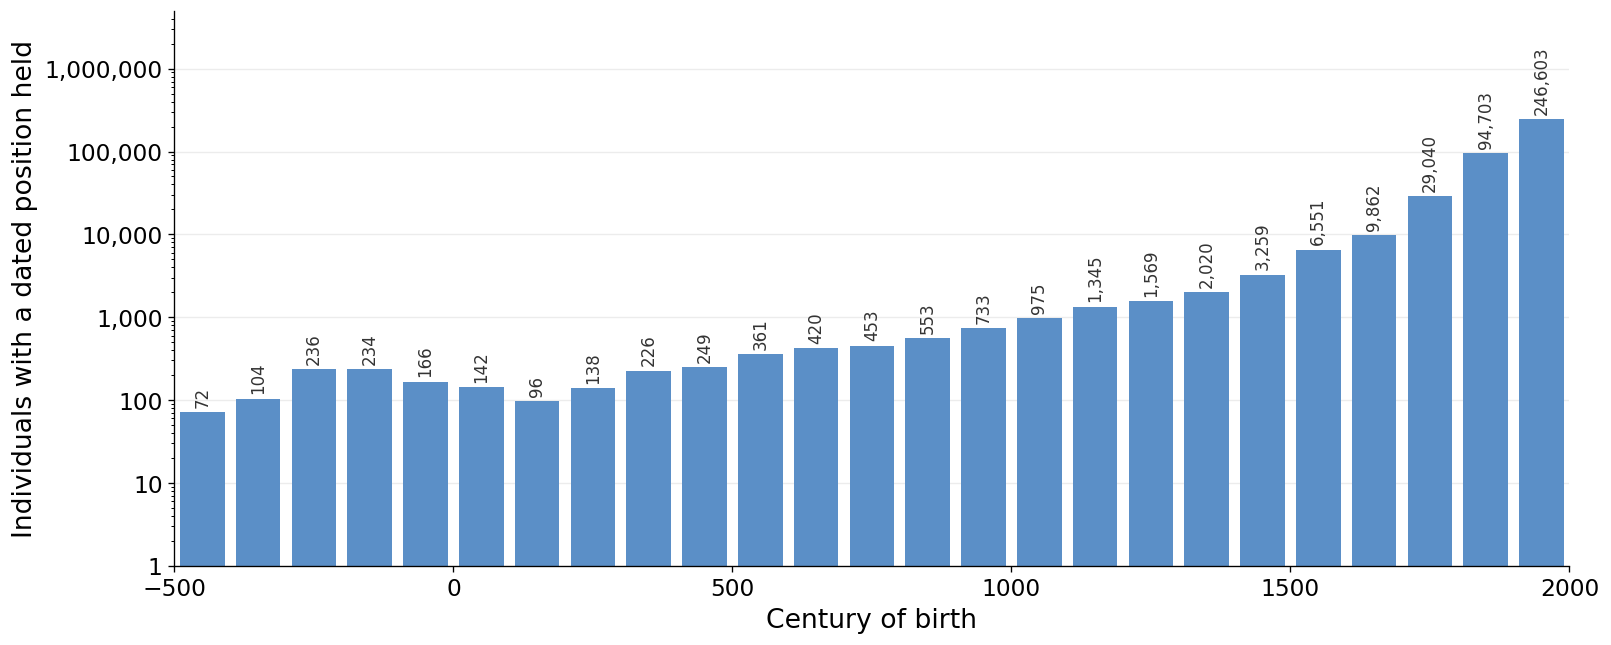

In [6]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.bar(per_century['century'] + CENTURY / 2, per_century['with a dated position'], width=CENTURY * 0.8, color=MAIN_COLOR)
for century, n in per_century.select('century', 'with a dated position').iter_rows():
    ax.text(century + CENTURY / 2, n * 1.15, f'{n:,}', ha='center', va='bottom', fontsize=VALUE_LABEL_FONTSIZE - 2, rotation=90, color=TEXT)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_ylim(1, per_century['with a dated position'].max() * 20)
ax.set_xlim(FIRST_CENTURY, LAST_CENTURY + CENTURY)
ax.set_xlabel('Century of birth')
ax.set_ylabel('Individuals with a dated position held')
ax.grid(axis='y')
plt.show()

### Figure 2: Share of the individuals born in each century with a dated position held

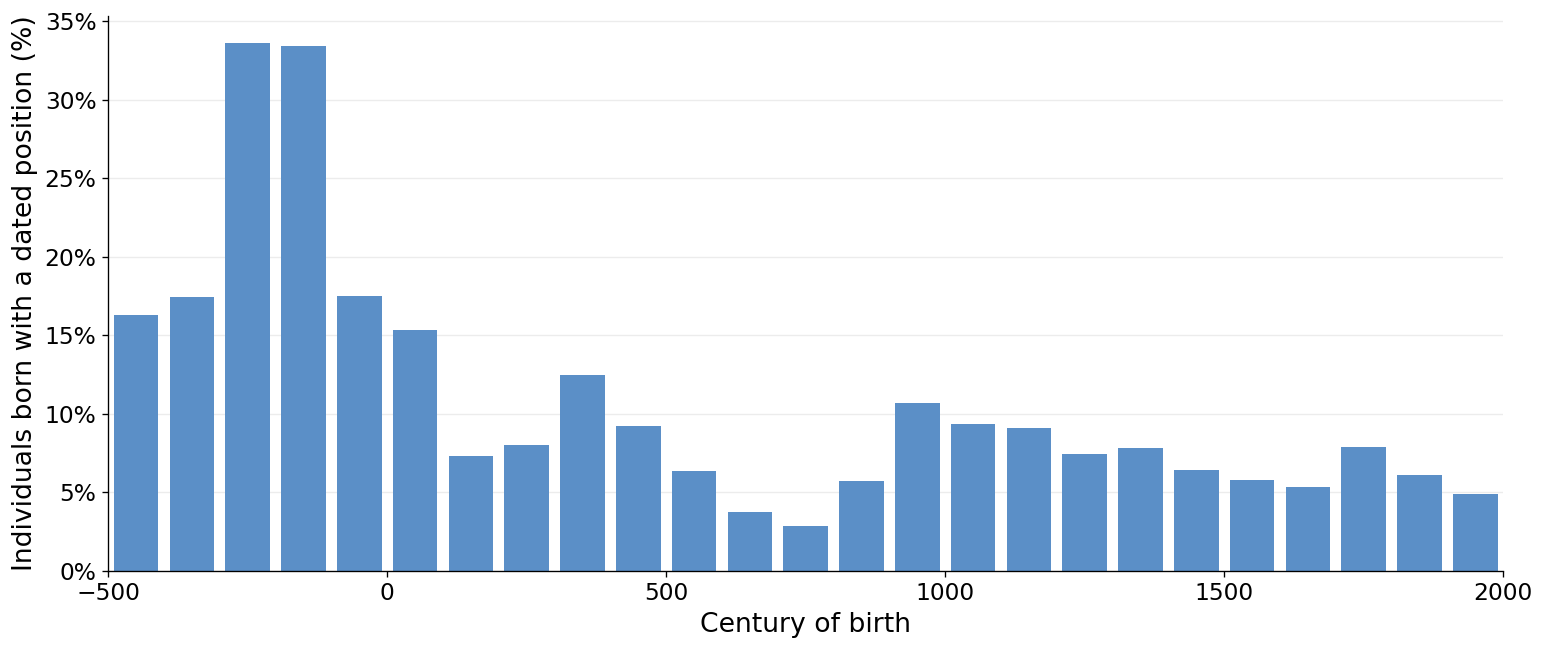

In [7]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.bar(per_century['century'] + CENTURY / 2, per_century['% of individuals born'], width=CENTURY * 0.8, color=MAIN_COLOR)
ax.set_xlim(FIRST_CENTURY, LAST_CENTURY + CENTURY)
ax.yaxis.set_major_formatter(PERCENT)
ax.set_xlabel('Century of birth')
ax.set_ylabel('Individuals born with a dated position (%)')
ax.grid(axis='y')
plt.show()

### Figure 3: Birth, positions held and death of the most-linked individuals born 700–799

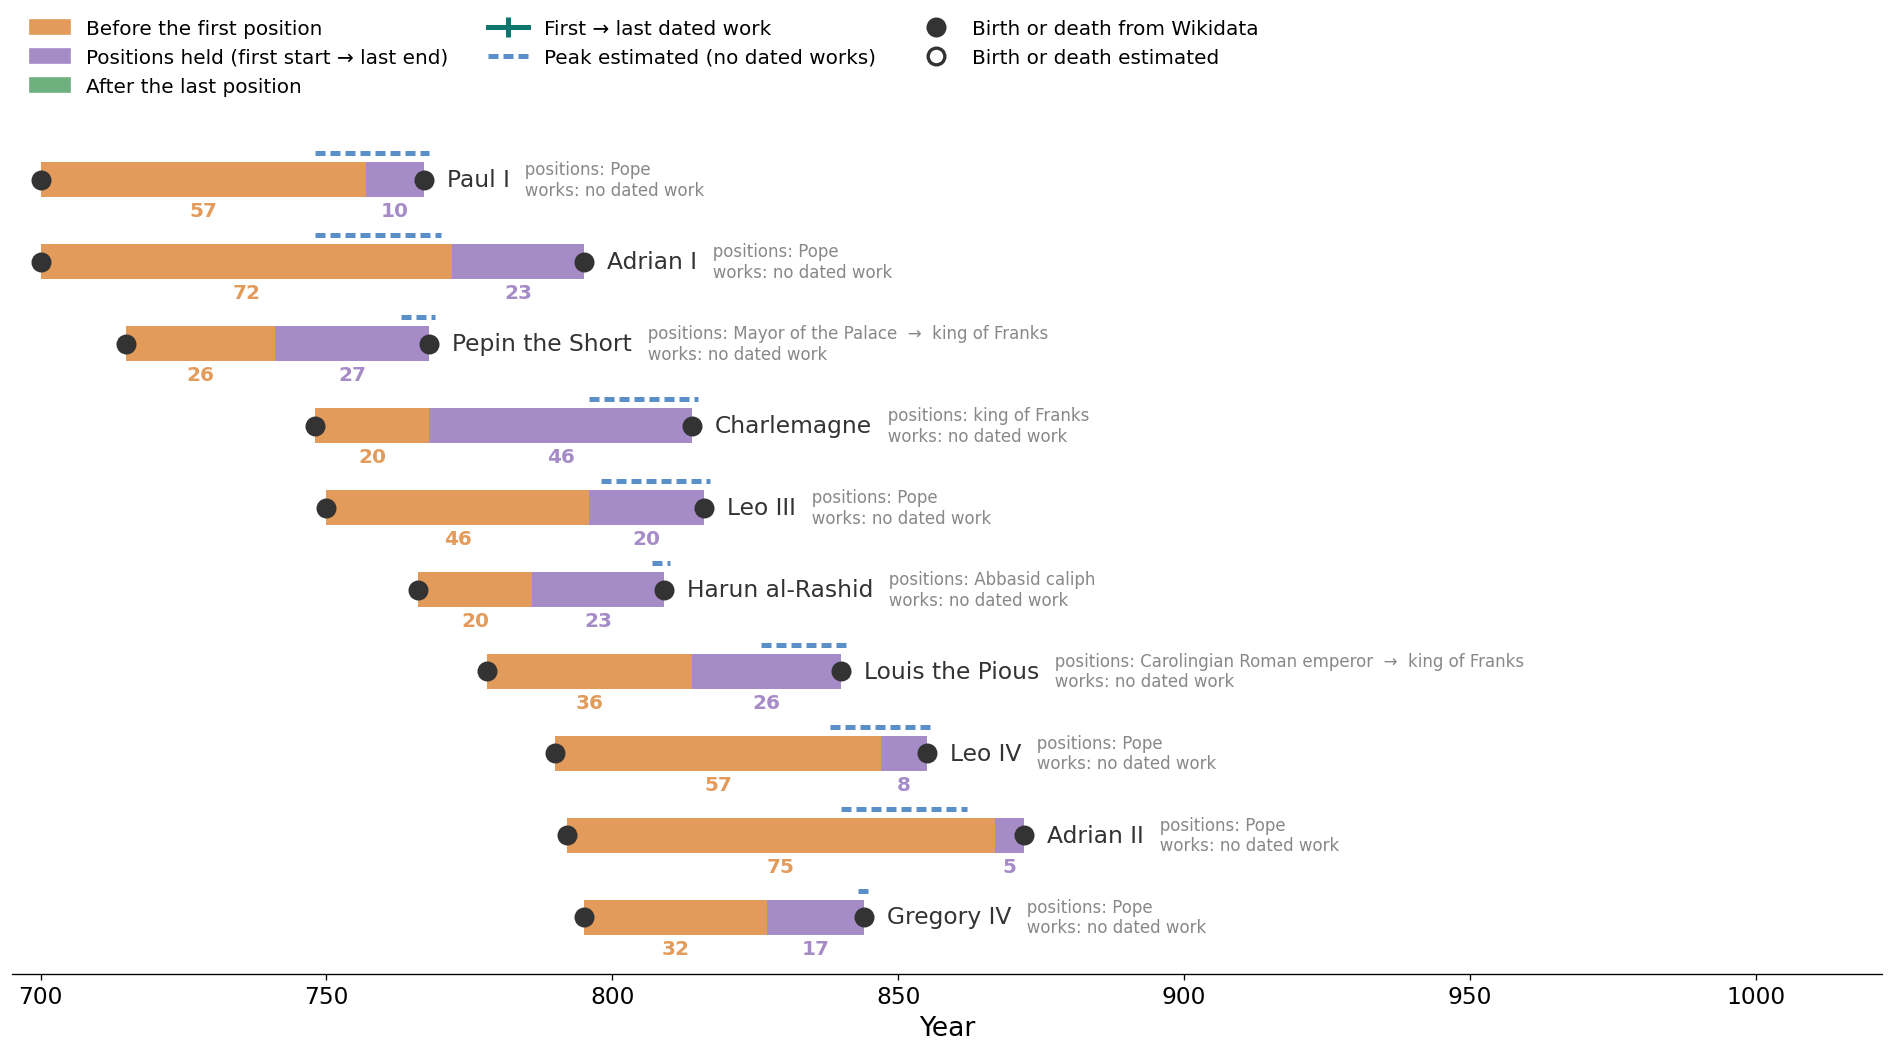

In [8]:
def shorten(text, size=45):
    return text if len(text) <= size else text[:size - 1] + '…'


def plot_lives(frame):
    fig, ax = plt.subplots(figsize=(16, 9))
    for row, person in enumerate(frame.iter_rows(named=True)):
        spans = [(person['birth_year'], person['first_position']), (person['first_position'], person['last_position']), (person['last_position'], person['death_year'])]
        for color, (start, end) in zip(SPAN_COLORS.values(), spans):
            if end > start:
                ax.barh(row, end - start, left=start, height=0.42, color=color)
                ax.text((start + end) / 2, row - 0.27, end - start, ha='center', va='top', fontsize=12, color=color, fontweight='bold')
        works = [person['peak_start'], person['peak_end'] + 1]
        if person['peak_source'] == 'dated works':
            ax.plot(works, [row + 0.32] * 2, color=TEAL, linewidth=3, marker='|', markersize=12, markeredgewidth=3)
        else:
            ax.plot(works, [row + 0.32] * 2, color=BLUE, linewidth=3, linestyle=(0, (2, 1)))
        for year, source in [(person['birth_year'], person['birth_source']), (person['death_year'], person['death_source'])]:
            ax.plot(year, row, 'o', markersize=10, markeredgewidth=2, color=TEXT, markerfacecolor='white' if source == 'estimated' else TEXT, zorder=3)
        name = ax.text(max(person['death_year'], person['last_position'], person['peak_end']) + 4, row, person['name'], va='center', fontsize=14, color=TEXT)
        positions = person['first_position_name'] if person['first_position_qid'] == person['last_position_qid'] else f"{person['first_position_name']}  →  {person['last_position_name']}"
        works = 'no dated work' if person['first_work_name'] is None else (
            person['first_work_name'] if person['first_work_name'] == person['last_work_name'] else f"{shorten(person['first_work_name'])}  →  {shorten(person['last_work_name'])}"
        )
        ax.annotate(f'   positions: {positions}\n   works: {works}', xycoords=name, xy=(1, 0.5), va='center', fontsize=10, color=MUTED_TEXT)
    ax.legend(handles=[
        *[Patch(color=color, label=label) for label, color in SPAN_COLORS.items()],
        Line2D([], [], color=TEAL, linewidth=3, marker='|', markersize=12, markeredgewidth=3, label='First → last dated work'),
        Line2D([], [], color=BLUE, linewidth=3, linestyle=(0, (2, 1)), label='Peak estimated (no dated works)'),
        Line2D([], [], marker='o', linestyle='', markersize=10, markeredgewidth=2, color=TEXT, label='Birth or death from Wikidata'),
        Line2D([], [], marker='o', linestyle='', markersize=10, markeredgewidth=2, color=TEXT, markerfacecolor='white', label='Birth or death estimated'),
    ], loc='lower left', bbox_to_anchor=(0, 1), ncol=3, fontsize=12)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.set_xlim(frame['birth_year'].min() - 5, frame['death_year'].max() + 150)
    ax.set_xlabel('Year')
    plt.tight_layout()
    plt.show()


plot_lives(examples['everyone'])

### Figure 4: Birth, positions held, dated works and death of the most-linked scientists born 1600–1699

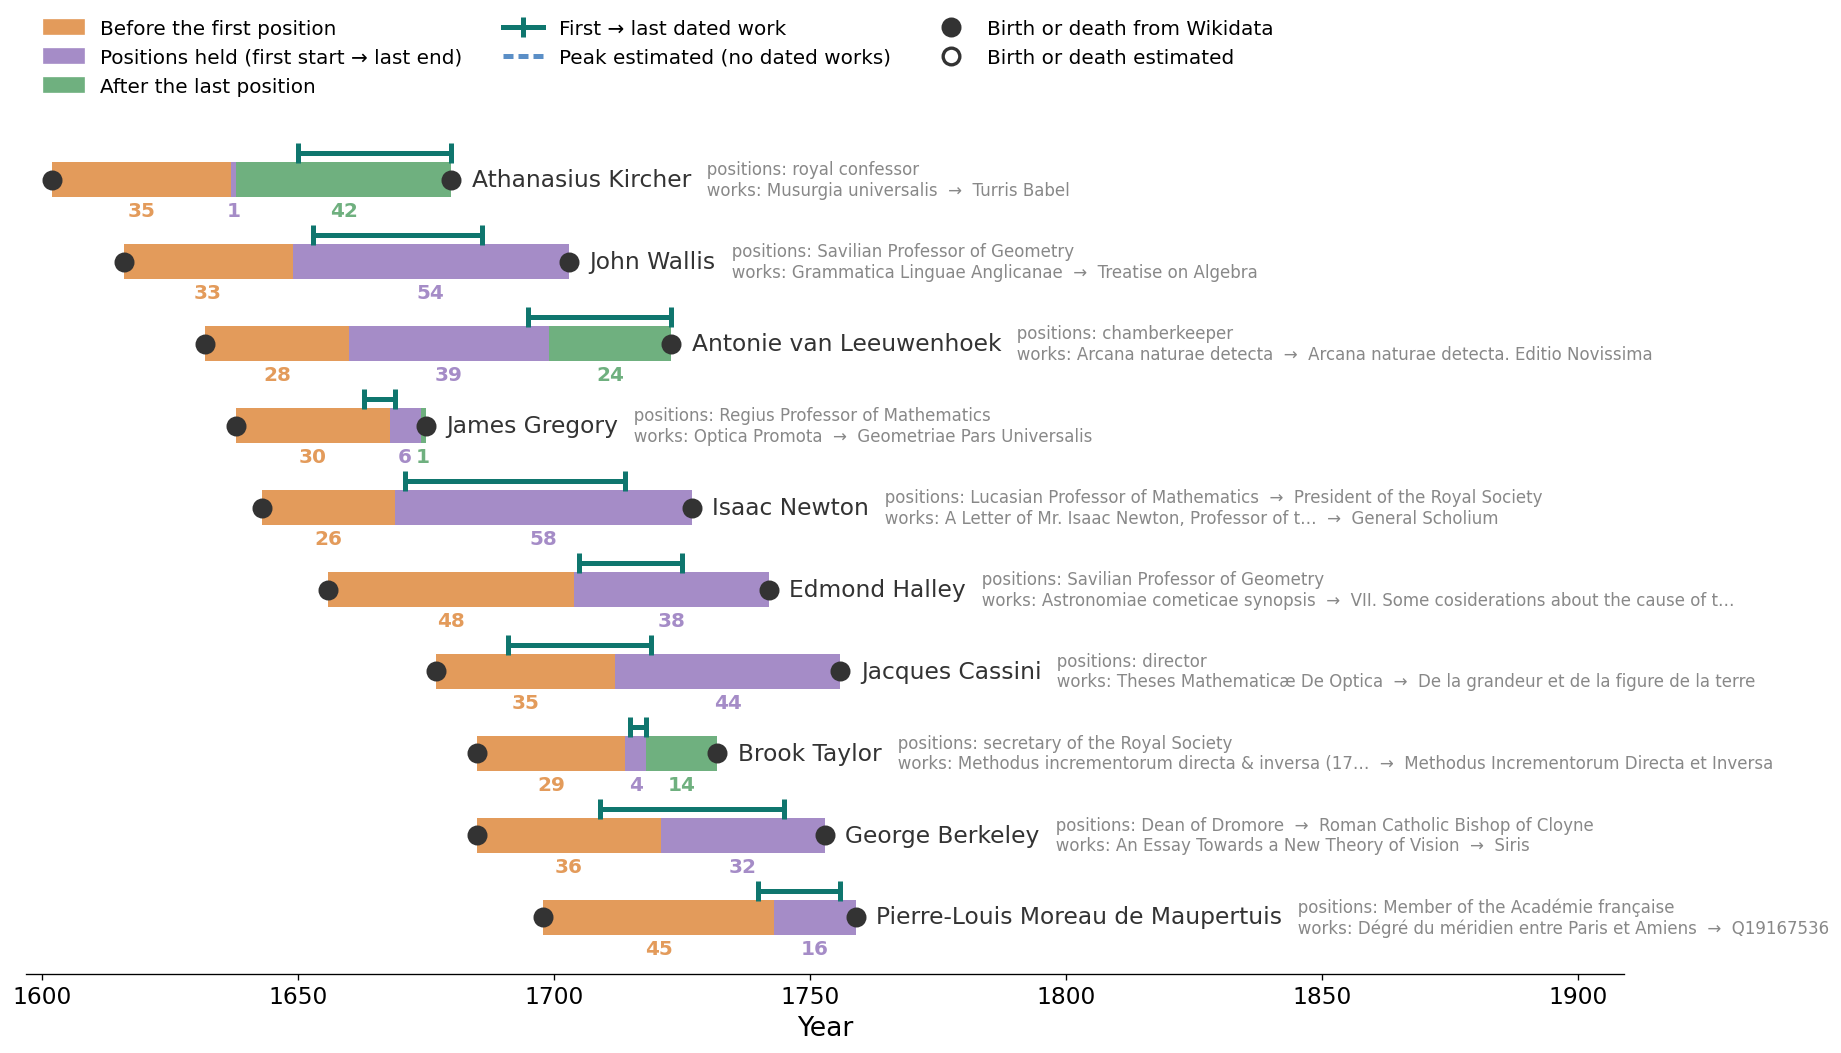

In [9]:
plot_lives(examples['scientists'])

### Figure 5: Birth, positions held, dated works and death of the most-linked artists born 1600–1699

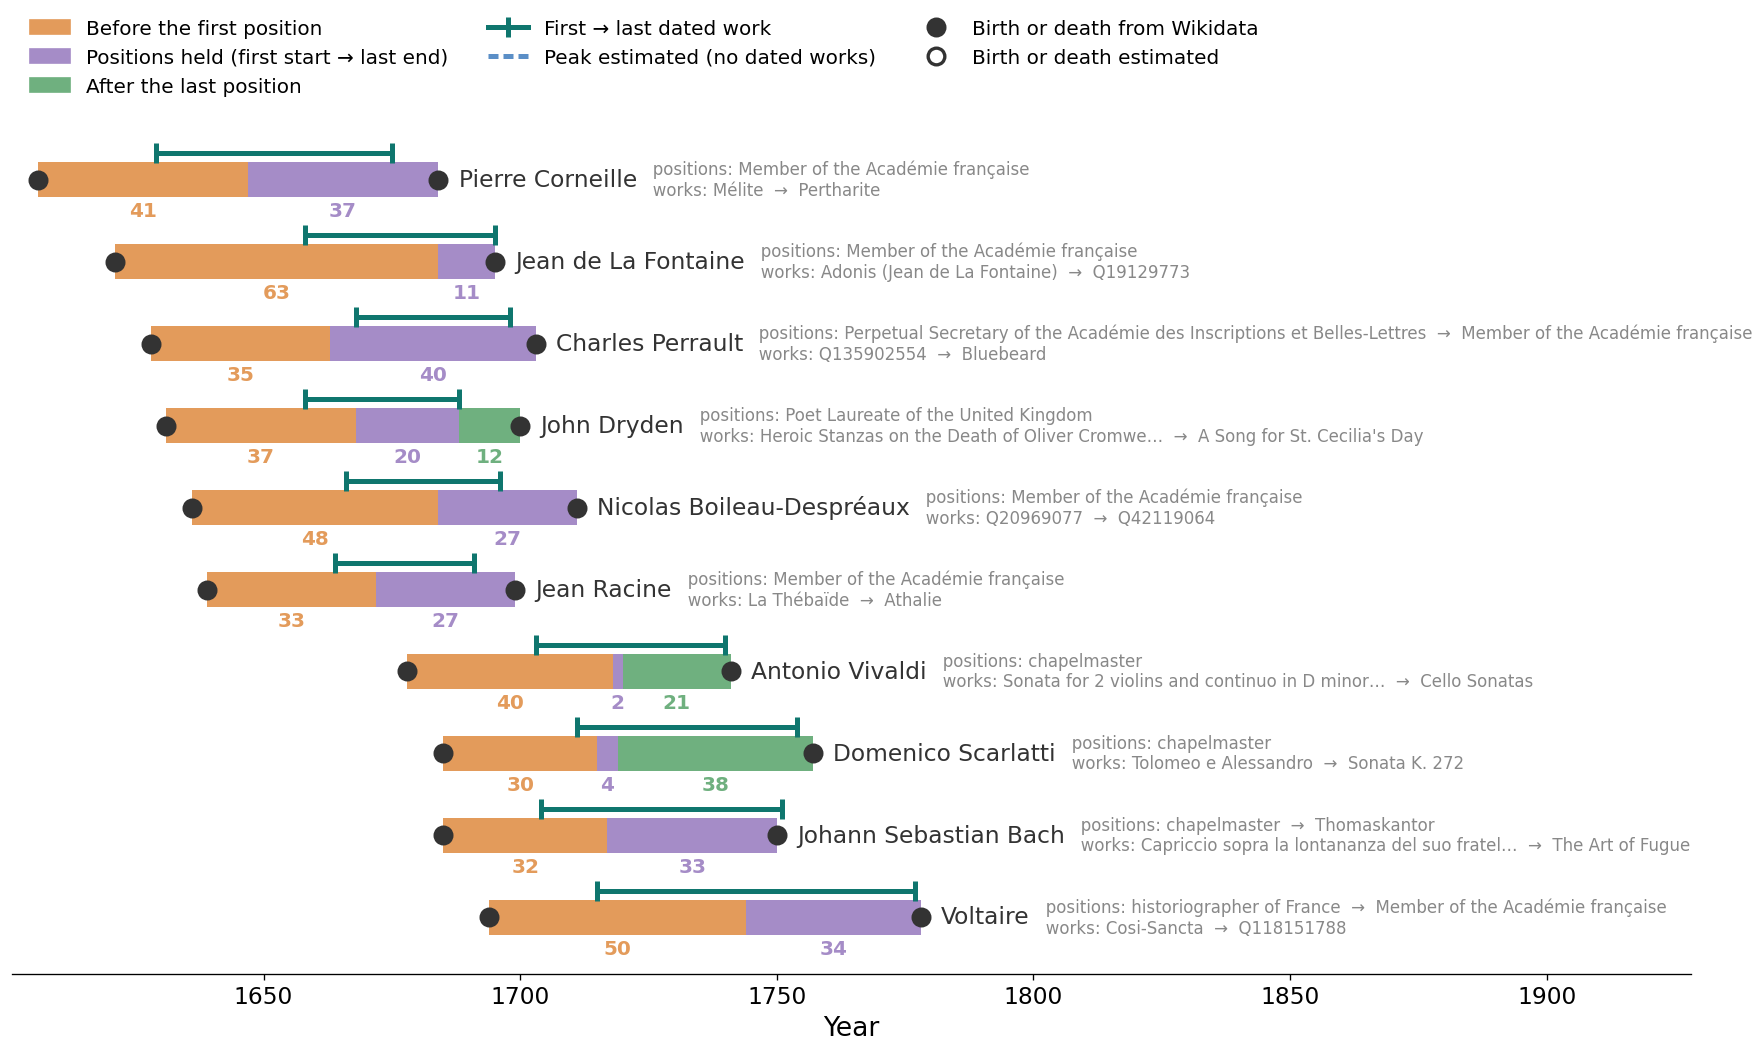

In [10]:
plot_lives(examples['artists'])